# Customer Churn Analysis and Classification

- Student: Farzana Asadi
- Student Number: U254N2745

In this project I analyse IBM Telco Customer churn to find the relation of customer behavior with churn.
- BlastChar. Telco Customer Churn. Kaggle. https://www.kaggle.com/datasets/blastchar/telco-customer-churn

## 1. Setup and Data Loading


### Check the Python environment and working directory
With the following checks that the notebook uses the projects .venv, which contains the python packages we installed for the project.

In [1]:
import sys
from pathlib import Path
import pandas as pd


current_dir = Path.cwd()

if (current_dir / "data" / "raw").is_dir():
    project_root = current_dir
elif (current_dir.parent / "data" / "raw").is_dir():
    project_root = current_dir.parent
else:
    raise FileNotFoundError("Could not locate the project root directory containing 'data/raw'.")

dataset_path = project_root / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

print(f"Project Root: {project_root}")
print(f"Dataset Path: {dataset_path}")
print("Python:", sys.executable)
print("pandas version:", pd.__version__)
print("Working directory:", Path.cwd())

Project Root: /Users/farzanadolatshahi/Documents/University/3rd Semester/Business Intelligence/Assignments/telco-customer-churn
Dataset Path: /Users/farzanadolatshahi/Documents/University/3rd Semester/Business Intelligence/Assignments/telco-customer-churn/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv
Python: /Users/farzanadolatshahi/Documents/University/3rd Semester/Business Intelligence/Assignments/telco-customer-churn/.venv/bin/python
pandas version: 3.1.1
Working directory: /Users/farzanadolatshahi/Documents/University/3rd Semester/Business Intelligence/Assignments/telco-customer-churn/notebooks


### Load the customer dataset
Locating the dataset and saving the path in data_path variable, and then load the dataset in a pandas DataFrame and and output the 5 top rows.

In [2]:


df = pd.read_csv(dataset_path)
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2.Inspection and cleaning

In [3]:
# dataframe dimensions and column types
print("Dataset shape:", df.shape)
print("------------------------------------")
df.info()

Dataset shape: (7043, 21)
------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str

The TotalCharges represents a monetary amount and should be numeric, but it is read as text(str), needs investigation.

### Find missing values and blank charges


In [4]:
print("Missing values per column:")
print(df.isna().sum())

# The TotalCharges column is str, but it should be numeric. check here for blank values in this column.
blank_total_charges = df["TotalCharges"].str.strip().eq("")

print("\nBlank TotalCharges values:", blank_total_charges.sum())

df.loc[
    blank_total_charges,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank TotalCharges values: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


11 TotalCharges are found blank, and displayed and shows the zero tenure and Churn = NO

But it does not prove their actual total charges were zero. Missing information and recorded 0 are different.

### Numeric conversion and verification
Convert the TotalCharges column to numeric and turn the values that can not be converted into missing value, rather than stopping with an error. This will convert the blank strings to NaN.

In [5]:
# Convert the TotalCharges column to numeric
numeric_total_charges = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing after conversion:", numeric_total_charges.isna().sum())
print(
    "Missing values match the known blanks:",
    numeric_total_charges.isna().equals(blank_total_charges)
)

Missing after conversion: 11
Missing values match the known blanks: True


There are still 11 values missing.
Knowing that 11 values are missing isnt enough by itself, they could have been different rows, with comparing masks confirms they are exactly the known blanks.

### Create the cleaned dataset
Create a copy of DataFrame so the main df remains available for comparison, and for the TotalCharges replaces the copied column with the numeric values. 
Then the rows with missing values are removed and with the subset limits the condition to the this specific column.


In [6]:
df_clean = df.copy()
df_clean["TotalCharges"] = numeric_total_charges
df_clean = df_clean.dropna(subset=["TotalCharges"]).copy()

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("TotalCharges type:", df_clean["TotalCharges"].dtype)
print("Remaining missing TotalCharges:", df_clean["TotalCharges"].isna().sum())

Original shape: (7043, 21)
Cleaned shape: (7032, 21)
TotalCharges type: float64
Remaining missing TotalCharges: 0


__Decision and limitations__

Approximately 0.16% of records are removed, instead of assuming their unknown charges were zero. This excludes those 11 zero-tenure customers.

### Check duplicates

In [7]:
print("Duplicate customer IDs:", df_clean["customerID"].duplicated().sum())
print("Duplicate full rows:", df_clean.duplicated().sum())

Duplicate customer IDs: 0
Duplicate full rows: 0


### Inspect category labels

Looks for unexpected labels, spelling variations, and blank strings. for consistency check.

In [8]:
categorical_columns = df_clean.select_dtypes(include=["str", "object"]).columns

for column in categorical_columns:
    if column != "customerID":
        print(f"{column}: {df_clean[column].unique()}")

print("SeniorCitizen:", df_clean["SeniorCitizen"].unique())

gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner: <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines: <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService: <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup: <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract: <StringArray>
['Month-to-month', 'One year', '

“No internet service” and “No phone service” are meaningful categories, not missing values.

## 3. Exploratory analysis

### Calculate class balance

In [9]:
churn_counts = df_clean["Churn"].value_counts()
churn_percentages = df_clean["Churn"].value_counts(normalize=True) * 100

print("Customer counts:")
print(churn_counts)

print("\nPercentages:")
print(churn_percentages.round(2))

Customer counts:
Churn
No     5163
Yes    1869
Name: count, dtype: int64

Percentages:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64


Stayed: 5,163 — 73.42%
Churned: 1,869 — 26.58%

The classes are imbalance. predicting "No Churn" or "stayed" for everyone gives 73.42% accuracy but finds no churners, which is why accuracy alone is not enough.

In [10]:
figures_path = project_root / "figures"
figures_path.mkdir(exist_ok=True)

### Plot class balance

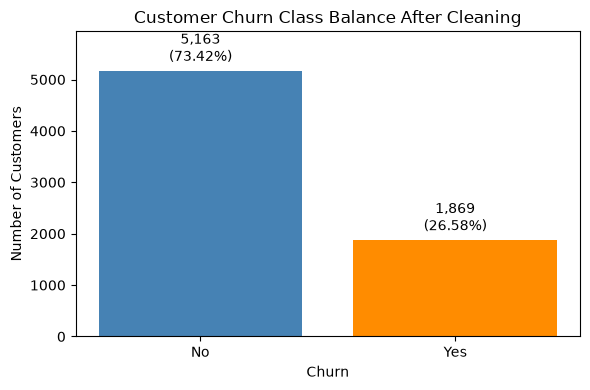

In [11]:
import matplotlib.pyplot as plt

churn_counts = df_clean["Churn"].value_counts().reindex(["No", "Yes"])

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(churn_counts.index, churn_counts.values, color=["steelblue", "darkorange"])

ax.set_title("Customer Churn Class Balance After Cleaning")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")

labels = [
    f"{count:,}\n({count / churn_counts.sum():.2%})"
    for count in churn_counts
]

ax.bar_label(ax.containers[0], labels=labels, padding=4)
ax.set_ylim(0, churn_counts.max() * 1.15)

fig.tight_layout()



fig.savefig(figures_path /"churn_class_balance.png", dpi=300, bbox_inches="tight")
plt.show()

### Calculate churn rates by contract
Create a frequency table for churn by contract type and calculate the percentage churned within each contract group.


In [12]:
# create frequency table of churn by contract type
contract_counts = pd.crosstab(df_clean["Contract"], df_clean["Churn"])

# row order
contract_counts = contract_counts.reindex(
    ["Month-to-month", "One year", "Two year"]
)

contract_counts["Total"] = contract_counts["No"] + contract_counts["Yes"]
contract_counts["ChurnRatePercent"] = (
    contract_counts["Yes"] / contract_counts["Total"] * 100
)

contract_counts.round(2)

Churn,No,Yes,Total,ChurnRatePercent
Contract,,,,
Month-to-month,2220,1655,3875,42.71
One year,1306,166,1472,11.28
Two year,1637,48,1685,2.85


Longer contracts are associated with lower observed churn. this does not mean or proof that extending a contract cause retention.

### Plot contract churn rates

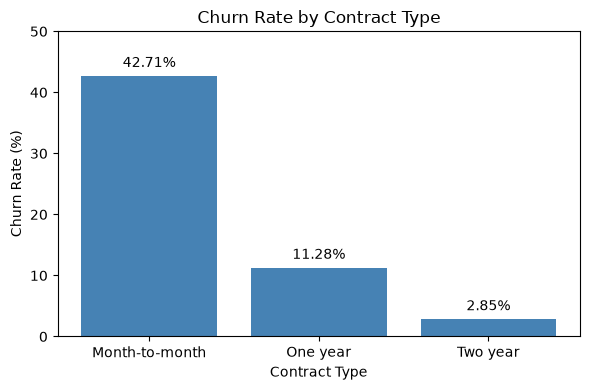

In [13]:

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(
    contract_counts.index,
    contract_counts["ChurnRatePercent"],
    color="steelblue"
)

ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 50)


ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
fig.tight_layout()
fig.savefig(figures_path /"churn_by_contract.png", dpi=300, bbox_inches="tight")
plt.show()

### Summarize numerical features by churn

In [14]:
numeric_summary = df_clean.groupby("Churn")[
    ["tenure", "MonthlyCharges"]
].agg(["count", "mean", "median"])

numeric_summary.round(2)

tenure               MonthlyCharges              
       count   mean median          count   mean median
Churn                                                  
No      5163  37.65   38.0           5163  61.31  64.45
Yes     1869  17.98   10.0           1869  74.44  79.65

Customers who churned generally had shorter tenure and higher charges.

### Plot tenure distributions

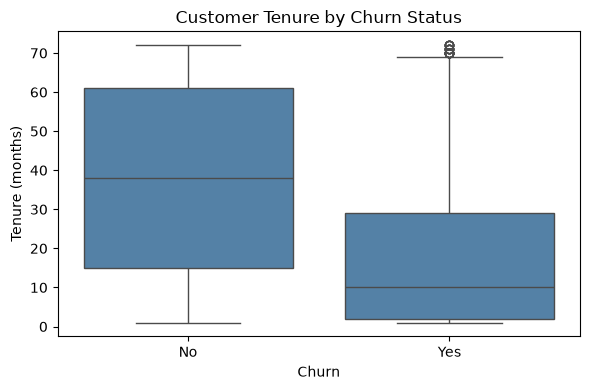

In [15]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(6, 4))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure",
    order=["No", "Yes"],
    color="steelblue",
    ax=ax
)

ax.set_title("Customer Tenure by Churn Status")
ax.set_xlabel("Churn")
ax.set_ylabel("Tenure (months)")

fig.tight_layout()
fig.savefig(figures_path /"tenure_by_churn.png", dpi=300, bbox_inches="tight")
plt.show()

Customers who churned generally had shorter tenure. Their median was 10 months, compared with 38 months for customers who stayed. The groups overlap, so tenure alone cannot identify every churner.

### Plot monthly-charge distributions

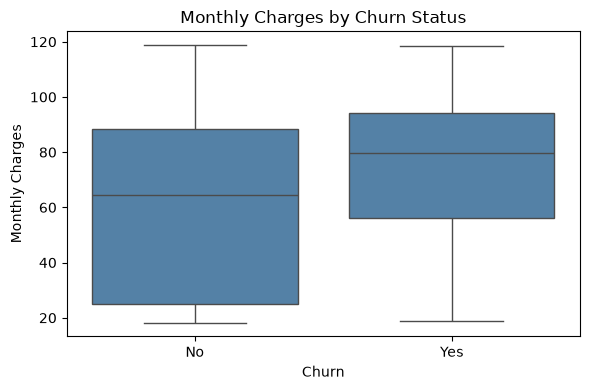

In [16]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(6, 4))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges",
    order=["No", "Yes"],
    color="steelblue",
    ax=ax
)

ax.set_title("Monthly Charges by Churn Status")
ax.set_xlabel("Churn")
ax.set_ylabel("Monthly Charges")

fig.tight_layout()
fig.savefig(figures_path /"monthly_charges_by_churn.png", dpi=300, bbox_inches="tight")
plt.show()

Customers who churned generally had higher monthly charges. Their median was 79.65, compared with 64.45 for customers who stayed. The overlap shows that higher charges do not always mean a customer will churn.

### Calculate numerical correlations

In [17]:
numeric_correlations = df_clean[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].corr()

numeric_correlations.round(2)

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


- Tenure–TotalCharges: 0.83.
- MonthlyCharges–TotalCharges: 0.65.
- Tenure–MonthlyCharges: 0.25.
- Accumulated charges tend to increase with relationship length and billing level. This doesn’t mean TotalCharges must exactly equal current MonthlyCharges multiplied by tenure.

## 4. Preparing the Classification Data (Task 2)

### Separate inputs and target

- Remove customerID because it is an identifier and wouldn't be a useful predictor since its only an arbitrary label. Also each id is unique and encoding could create create extra columns and the model could encourage learning patterns that don't generalize.
- Remove Churn because it is the answer to predict.
- Keep 19 customer features.

- Map text labels to numbers for churn
    - No --> 0 customer stayed 
    - Yes --> 1 customer churned (the outcome to be detected)


In [18]:
X = df_clean.drop(columns=["customerID", "Churn"])
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

print("Input shape:", X.shape)
print("Target counts:")
print(y.value_counts())

Input shape: (7032, 19)
Target counts:
Churn
0    5163
1    1869
Name: count, dtype: int64


### Split customers into training and test sets
The Scikit-learn is the chosen library for this assignment.
- Reserve the 20% for testing, use the remaining 80% for training.

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training inputs:", X_train.shape)
print("Test inputs:", X_test.shape)

print("\nTraining target percentages:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest target percentages:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training inputs: (5625, 19)
Test inputs: (1407, 19)

Training target percentages:
Churn
0    73.42
1    26.58
Name: proportion, dtype: float64

Test target percentages:
Churn
0    73.42
1    26.58
Name: proportion, dtype: float64


Results: 5,625 training and 1,407 test customers.
- The dataset is fully explored before splitting, the fitted preprocessing and models don't use test data, but the test data wasn't completely unseen during exploratory analysis.

stratify=y preserve class proportion and random_state = 42 makes split repeatable. 

### Define preprocessing column groups

column groups for correct treatment later on for the preprocessing,

In [20]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 5625 entries, 1413 to 1505
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5625 non-null   str    
 1   SeniorCitizen     5625 non-null   int64  
 2   Partner           5625 non-null   str    
 3   Dependents        5625 non-null   str    
 4   tenure            5625 non-null   int64  
 5   PhoneService      5625 non-null   str    
 6   MultipleLines     5625 non-null   str    
 7   InternetService   5625 non-null   str    
 8   OnlineSecurity    5625 non-null   str    
 9   OnlineBackup      5625 non-null   str    
 10  DeviceProtection  5625 non-null   str    
 11  TechSupport       5625 non-null   str    
 12  StreamingTV       5625 non-null   str    
 13  StreamingMovies   5625 non-null   str    
 14  Contract          5625 non-null   str    
 15  PaperlessBilling  5625 non-null   str    
 16  PaymentMethod     5625 non-null   str    
 17  MonthlyC

In [21]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

categorical_features = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

binary_features = ["SeniorCitizen"]

print("Numeric:", numeric_features)
print("Categorical:", categorical_features)
print("Binary:", binary_features)

print(
    "Total features:",
    len(numeric_features) + len(categorical_features) + len(binary_features)
)

Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Binary: ['SeniorCitizen']
Total features: 19


## 5. Preprocessing and Training

### Define preprocessing instructions
The following instructions are created to be used later.
- The numeric features are in different scales and should be standardized. 
- The categorical features need one-hot encoding because the model needs the numeric values but we can not just give the arbitrary numbers (imposing an unsupported numerical order), to avoid that instead I use encoder to create one indicator column per category.
- SeniorCitizen is passed through unchanged.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("binary", "passthrough", binary_features)
    ]
)

I used StandardScaler to put tenure, monthly charges, and total charges on comparable scales. The scaler learns from the training data, and the same settings are applied to the test data.

### Train Logistic Regression

For the 2 binary classification model asked in the assignment instructions, for the first model I chose Logistic Regression classification model, with creating a pipeline that prepares the features and then trains the Logistic Regression.

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

### Train Random Forest
For the second model I chose the Random Forest.
- I used 200 trees as a practical starting configuration. The number of trees was not tuned.

In [24]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline(
    steps=[
        ("preprocessing", clone(preprocessor)),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

## 6. Model Evaluation

### Generate test predictions
I used predict_proba() to estimate churn probabilities for the test customers, selecting class 1 with [:, 1]. I also used predict() to obtain the final labels: 0 for stayed and 1 for churned. Both pipelines reuse the preprocessing learned during training; no retraining occurs during prediction.

In [25]:
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]
forest_probabilities = forest_model.predict_proba(X_test)[:, 1]

logistic_predictions = logistic_model.predict(X_test)
forest_predictions = forest_model.predict(X_test)

print("Logistic Regression probabilities:", logistic_probabilities[:5])
print("Random Forest probabilities:", forest_probabilities[:5])

print("Logistic Regression predictions:", logistic_predictions[:5])
print("Random Forest predictions:", forest_predictions[:5])

Logistic Regression probabilities: [0.01761076 0.5921694  0.00484055 0.20177286 0.10216166]
Random Forest probabilities: [0.01       0.805      0.005      0.08508333 0.09      ]
Logistic Regression predictions: [0 1 0 0 0]
Random Forest predictions: [0 1 0 0 0]


### Calculate performance metrics

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, predictions, probabilities in [
    ("Logistic Regression", logistic_predictions, logistic_probabilities),
    ("Random Forest", forest_predictions, forest_probabilities)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.8045,0.6495,0.5749,0.6099,0.8359
Random Forest,0.7861,0.6246,0.4893,0.5487,0.8128


I compared each model’s test predictions with y_test using accuracy, precision, recall, and F1. ROC-AUC was calculated from churn probabilities. A loop applies the same evaluation to both models and stores the results in a table.


### Plot ROC curves

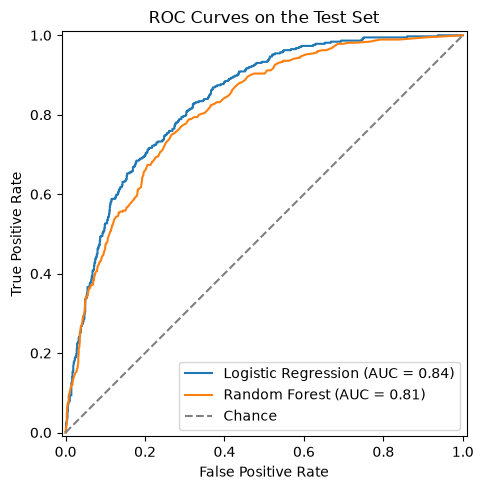

In [27]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    y_test,
    logistic_probabilities,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    forest_probabilities,
    name="Random Forest",
    ax=ax
)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")

ax.set_title("ROC Curves on the Test Set")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(loc="lower right")

fig.tight_layout()
fig.savefig(figures_path /"roc_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

I plotted both ROC curves using test churn probabilities. Logistic Regression achieved the higher ROC-AUC on this split. Both curves lie above the chance diagonal, but neither model perfectly separates churners from customers who stayed.